# Radio-map estimation extension: real multi-building data, harder targets, GAT/Delaunay, outage metrics, cross-layout transfer

**Why a new notebook.** `radiomap_6g_sweep.ipynb` stays as the DeepMIMO record (its numbers are not reused). This one covers the five gaps found in the review:
real measurements (UJIIndoorLoc, 3 buildings), a harder DeepMIMO target (narrowband channel power, NLOS scenarios), GAT + Delaunay vs kNN,
outage/coverage metrics, and leave-one-building-out transfer of pre-trained GNNs.

**Needs next to it:** `rmbench_core.py`, `rmbench_nn.py`, `rmbench_ext.py`, `run_ext.py` (no changes to the first two).

**Provenance.** The pipeline was dry-run on a *fake* file with the UJIIndoorLoc schema and on synthetic DeepMIMO-style units (0 failed jobs; the fake data is noise, so it says nothing about science).
The UCI download, the real UJI results, DeepMIMO `narrowband` / the `i3_60` slug have **not** been run. Every number below comes from the cell above it.

**Pre-specified before any result:** contrast lists `TOPO` and `XFER` (30 tests each, cap 36, Holm), outage thresholds (train-label 10th/25th percentile; -85 dBm UJI, -77 dBm DeepMIMO), no hyper-parameter tuning, parent = building-floor (never the AP).

## 1. Setup

In [1]:
import os, sys, json, warnings
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import rmbench_core as rc, rmbench_ext as rx, run_ext as rr

SMOKE = False            # True: ~5 min dry run on FAKE UJI-format data. Set False for the real experiments.
BLOCKED = True         # True: contiguous-block test region instead of random test points (run both for the paper)
N_JOBS = max(1, (os.cpu_count() or 2) - 1)
PRETRAIN_STEPS = 1500
split = dict(split_mode="blocked", block_buffer=0.0) if BLOCKED else {}
sfx = "_blocked" if BLOCKED else ""
print("SMOKE" if SMOKE else "REAL", "| blocked:", BLOCKED, "| jobs:", N_JOBS)

REAL | blocked: True | jobs: 15


## 2. Real data: UJIIndoorLoc units

One unit = one Wi-Fi AP on one floor of one building; **layout = building**; **parent = building-floor** (APs on a floor share reference points, so the floor is the statistical unit).
Repeated captures at a reference point are collapsed to the median RSSI of detections (>= 50% detection). AP positions are unknown: they are estimated per task **from the labeled set only**.
RSSI 100 (not detected) points are absent, so coverage statements are conditional on detection.

In [2]:
if SMOKE:
    import shutil
    shutil.rmtree("nb_smoke", ignore_errors=True)
    UJI = dict(rx.UJI_CFG, cache_dir="nb_smoke/uji", densities=(10, 20, 30), n_rep=2, n_test=25, min_unit_points=50, uji_max_waps_per_floor=2, **split)
    csv_dir = rx.make_fake_uji("nb_smoke/fake_uji", floors=(2, 2, 2), n_waps=12); OUT = "nb_smoke/results"; STEPS, N_EVAL, N_SRC = 60, 3, 8
else:
    UJI = dict(rx.UJI_CFG, **split); csv_dir = rx.fetch_uji("data/ujiindoorloc"); OUT = "results_ext_uji"
    STEPS, N_EVAL, N_SRC = PRETRAIN_STEPS, 20, 40
os.makedirs(OUT, exist_ok=True)
ok, dropped = rx.build_uji_units(UJI, csv_dir)
meta = pd.DataFrame([dict(unit=n, layout=(u := rx.get_unit_ext(n, UJI["cache_dir"]))["layout"], parent=u["parent"], n_pts=len(u["y"]), y_std=u["y"].std()) for n in ok])
print(f"{len(ok)} units | {meta.parent.nunique()} building-floors | {meta.layout.nunique()} buildings")
display(meta.groupby("layout").agg(units=("unit", "size"), floors=("parent", "nunique"), median_pts=("n_pts", "median"), y_std=("y_std", "mean")).round(2))

13 units | 2 building-floors | 2 buildings


,units,floors,median_pts,y_std
layout,,,,
uji_b0,7,1,122.0,12.25
uji_b2,6,1,121.5,9.36


## 3. Topology and architecture grid (within layout)

Methods: `trend`, `idw`, `krig_global`, `kgnn`, and label-aware `gcn`/`gat` on kNN(8) vs Delaunay, plus an IDW-anchored hybrid GAT (`gat_del_idw`). All predict the same trend residual and see identical labeled/test sets.

In [3]:
df_grid = rr.run_grid(ok, UJI, OUT, "uji_grid" + sfx, N_JOBS)
rr.report(df_grid.assign(scenario="uji"), OUT, rr.TOPO, "uji_grid" + sfx)

[run_tasks_ext] 195 tasks, 195 done, 0 to run (n_jobs=15)

##### uji_grid_blocked: 1755 job rows, 1755 ok, 0 failed

=== RMSE (dB), parent-level mean
name              gat_del  gat_del_idw  gat_knn  gcn_del  gcn_knn     idw    kgnn  krig_global   trend
scenario density                                                                                      
uji      15        16.580       12.986   17.895   15.169   15.898  12.674  12.706       12.675  27.373
         30        12.238       12.263   12.136   11.707   12.102  11.774  12.025       11.841  11.773
         60        10.691       10.783   11.087   10.398   10.579  10.271  10.431       10.296  10.199

=== MAE (dB)
name              gat_del  gat_del_idw  gat_knn  gcn_del  gcn_knn     idw    kgnn  krig_global   trend
scenario density                                                                                      
uji      15        14.116       11.298   14.649   12.941   13.699  11.003  11.033       11.000  25.714
         30 

### 3a. Plot: RMSE and outage-F1 vs labeled density

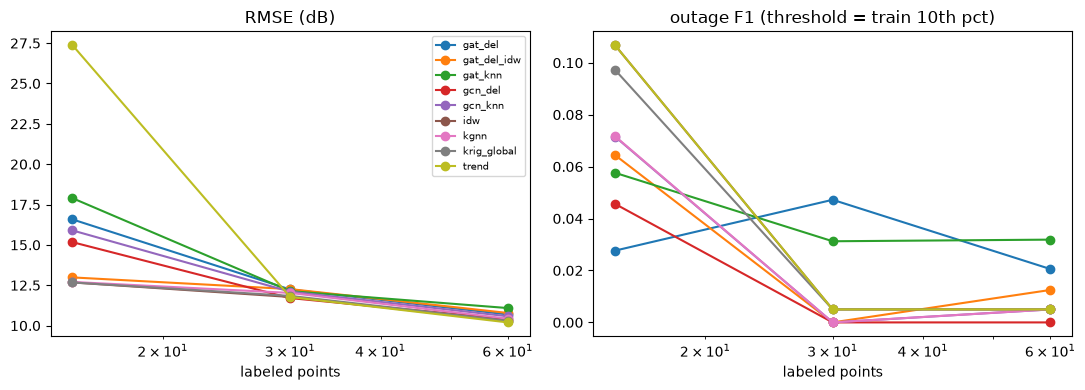

In [4]:
r = rx.agg_metric(df_grid.assign(scenario="uji"), "rmse"); f = rx.agg_metric(df_grid.assign(scenario="uji"), "f1_q10")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m in r.columns:
    ax[0].plot(r.index.get_level_values("density"), r[m], marker="o", label=m); ax[1].plot(f.index.get_level_values("density"), f[m], marker="o", label=m)
for a, t in zip(ax, ["RMSE (dB)", "outage F1 (threshold = train 10th pct)"]): a.set_xscale("log"); a.set_xlabel("labeled points"); a.set_title(t)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. Cross-layout generalisation (leave-one-building-out)

For each held-out building, GNNs are **pre-trained** with episodic masked-label training on units of the *other* buildings (`xfer_*`, zero-shot; `xferft_*`, +30 fine-tune steps).
Controls: `within_*` (pre-trained on other units of the same building; the transfer gap is `xfer` minus `within`) and scratch-trained GNNs (value of pre-training).
Evaluation units are never in any source set. Inference is on the pooled `ALL` block (parents = floors); with 3 buildings, per-building rows are descriptive only (min attainable p with 3 clusters = 0.25).

In [5]:
df_lolo = rr.run_lolo(ok, UJI, OUT, "uji_lolo" + sfx, N_JOBS, STEPS, N_EVAL, N_SRC)
rr.report(rx.by_layout(df_lolo), OUT, rr.XFER, "uji_lolo" + sfx, pooled_only=True)

leave-one-layout-out plan (layout, n_eval, n_cross_src, n_within_src): [('uji_b0', 7, 6, 0), ('uji_b2', 6, 7, 0)]
[run_tasks_ext] 195 tasks, 195 done, 0 to run (n_jobs=15)

##### uji_lolo_blocked: 3900 job rows, 3900 ok, 0 failed

=== RMSE (dB), parent-level mean
name              gat_del  gcn_knn     idw    kgnn  krig_global   trend  xfer_gat_del  xfer_gcn_knn  xferft_gat_del  xferft_gcn_knn
scenario density                                                                                                                   
ALL      15        16.580   15.898  12.674  12.706       12.675  27.373        31.669        38.425          17.411          26.936
         30        12.238   12.102  11.774  12.025       11.841  11.773        11.945        11.887          11.736          11.760
         60        10.691   10.579  10.271  10.431       10.296  10.199        10.438        10.230          10.278          10.325
uji_b0   15        22.292   20.626  14.225  14.358       14.275  43.568     

## 5. Harder simulated target: DeepMIMO narrowband channel power

Same methods on `power_def="narrowband"` (single antenna pair / subcarrier, small-scale fading included). `i2_28b` is all-NLOS (1 transmitter), `i3_60` has a LOS room and an NLOS hallway (2 transmitters, slug assumed),
`i1_2p5` has many. Only `i1_2p5` supports paired tests; layout and carrier frequency are confounded, so no cross-layout claim from this section. Skipped in smoke mode (needs deepmimo.net).

In [6]:
RUN_DEEPMIMO = not SMOKE
if RUN_DEEPMIMO:
    DM = dict(rx.DM_HARD_CFG, cache_dir="rmbench_cache_dm_nb", **split); out_dm = "results_ext_dm"; os.makedirs(out_dm, exist_ok=True)
    ok_dm, dropped_dm = rx.build_dm_units(["i1_2p5", "i2_28b", "i3_60"], DM)
    for n, why in dropped_dm: print("dropped:", n, "-", why)
    by = rx.layouts_of(ok_dm, DM["cache_dir"]); ok_dm = [n for v in by.values() for n in v[:24]]
    U = [rx.get_unit_ext(n, DM["cache_dir"]) for n in ok_dm]
    display(pd.DataFrame([dict(scenario=u["scenario"], f_ghz=u["freq_ghz"], los_frac=u["los"].mean(), y_std=u["y"].std()) for u in U]).groupby("scenario").mean().round(3))
    df_dm = rr.run_grid(ok_dm, DM, out_dm, "dm_grid" + sfx, N_JOBS)
    # paired inference only on i1_2p5 (many transmitters = many parents); i2_28b (1 tx) and i3_60 (2 tx) are descriptive
    rr.report(df_dm, out_dm, rr.TOPO, "dm_grid" + sfx, infer=["i1_2p5"])
else:
    print("DeepMIMO section skipped (SMOKE mode).")

Scenario "i1_2p5" already exists in /home/praaneshnair/gitProjects/prism/deepmimo_scenarios
Loading TXRX PAIR: TXset 2 (tx_idx 0) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 1) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 2) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 3) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 4) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 5) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 6) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 7) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 8) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 9) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 10) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 11) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 12) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 13) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXs

Generating channels: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:00<00:00, 1929.52it/s]


Scenario "i2_28b" already exists in /home/praaneshnair/gitProjects/prism/deepmimo_scenarios
Loading TXRX PAIR: TXset 1 (tx_idx 0) & RXset 0 (rx_idxs 3000)


Generating channels: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 96.66it/s]

Scenario "i3_60" already exists in /home/praaneshnair/gitProjects/prism/deepmimo_scenarios
Loading TXRX PAIR: TXset 2 (tx_idx 0) & RXset 0 (rx_idxs 3000)


Loading TXRX PAIR: TXset 3 (tx_idx 0) & RXset 0 (rx_idxs 3000)


Generating channels: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:00<00:00, 1531.75it/s]


,f_ghz,los_frac,y_std
scenario,,,
i1_2p5,2.5,1.000,3.004
i2_28b,28.0,0.000,3.199
i3_60,60.0,0.993,3.059


[run_tasks_ext] 405 tasks, 405 done, 0 to run (n_jobs=15)

##### dm_grid_blocked: 3645 job rows, 3645 ok, 0 failed

=== RMSE (dB), parent-level mean
name              gat_del  gat_del_idw  gat_knn  gcn_del  gcn_knn    idw   kgnn  krig_global  trend
scenario density                                                                                   
i1_2p5   30         3.217        3.208    3.188    3.114    3.048  2.934  3.024        2.934  2.901
         100        2.904        2.901    2.929    2.880    2.877  2.825  2.983        2.811  2.798
         300        2.835        2.837    2.843    2.852    2.833  2.811  2.971        2.769  2.773
i2_28b   30         3.263        3.167    3.442    3.064    3.543  3.055  3.157        2.989  2.939
         100        3.151        3.066    3.120    3.092    3.110  3.023  3.099        2.985  2.939
         300        3.039        3.056    3.029    3.131    3.061  2.986  3.210        2.985  2.942
i3_60    30         3.063        3.065    3.090    

## 6. Limitations and threats to validity

- **Real data is Wi-Fi RSSI** (2.4/5 GHz, 25 phones, many users, integer dBm), not 6G. It tests the *method* on real, noisy, multi-building propagation; it does not make a 6G claim.
- **Unknown AP positions** are estimated from the labeled set; the estimate is noisy at 15 labels and is shared by all methods through the trend. The `trend` row shows how much it already explains.
- **Censoring:** undetected points are absent, so coverage/outage is conditional on detection.
- **Statistical units:** floors (about 13) for inference; buildings (3) descriptive only. Floors in one building are not independent draws of "building type".
- **No tuning:** neural models use library defaults; a loss to IDW could partly be under-tuning. Tune on disjoint units before claiming otherwise.
- **DeepMIMO:** `narrowband` assumes `compute_channels()` returns `(N, rx, tx, subcarriers)`; run `rx.target_diagnostic`-style checks on your install. Scenario slugs beyond `i1_2p5`, `i2_28b` are unverified.
- **Pre-training budget** (1500 steps, <= 40 source units) is small; the zero-shot GNN may be limited by it rather than by transfer itself.